# FFNN regression — predicting the final collision risk

**FYS-STK3155, Project 3.** Data: the ESA Collision Avoidance Challenge
conjunction data messages (CDMs).

## The question

The companion notebook `FFNN_classification.ipynb` asks a yes/no question: will
this conjunction end up above $\log_{10} P_c = -6$? Here we ask the harder one:

$$\hat{r} \approx r_{\text{final}} = \log_{10} P_c \text{ in the CDM closest to TCA},$$

again using only CDMs issued at least two days before TCA. The target is the
**continuous** risk — never thresholded, never cast to `int`.

## What makes this hard

The risk scale is **censored**: 82 % of events end at exactly $-30$, the
reporting floor. The target is therefore not a smooth continuum but a point
mass at $-30$ with a thin tail reaching up towards $-2$. A model that predicts
$-30$ for everything already explains most of the variance, so $R^2$ computed
over all events is close to meaningless on its own. Every result below is
therefore reported **three ways**:

| Subset | Why |
|---|---|
| all events | the headline number, dominated by the floor |
| $r_{\text{final}} > -30$ | the events that carry actual information |
| $r_{\text{final}} \ge -6$ | the high-risk region we actually care about |

## Notebook outline

| § | Experiment |
|---|---|
| 1 | Setup, data loading, event-level split |
| 2 | Exploratory data analysis (target, history, PCA) |
| 3 | Activation function × weight initialisation (3×3) |
| 4 | Network architecture |
| 5 | L1 vs. L2 regularisation |
| 6 | Bootstrap bias–variance decomposition |
| 7 | Learning curves of the selected model |
| 8 | Final held-out test evaluation |
| 9 | Benchmark against classical baselines |

## 1. Setup

In [1]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch

sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid

import ffnn_core as fc
import plot_style as ps
import read_data as rd

warnings.filterwarnings("ignore", category=UserWarning)
ps.apply_style()

### Experiment configuration

In [2]:
SEED = 3155

FEATURE_MODE = "latest"
INCLUDE_CURRENT_RISK = True
VAL_SIZE, TEST_SIZE = 0.15, 0.15

BASE_HIDDEN = (100, 100)
BASE_ACTIVATION = "relu"
BASE_INIT = "he"
BASE_LR = 1e-3
BATCH_SIZE = 64
MAX_EPOCHS = 150
PATIENCE = 20
GRAD_CLIP = 5.0

CV_FOLDS = 5
N_JOBS = 7
N_BOOTSTRAP = 20          # bias-variance resamples per complexity

RESULTS_DIR = Path("..") / "results" / "regression"
(RESULTS_DIR / "figures").mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / "tables").mkdir(parents=True, exist_ok=True)

torch.set_num_threads(1)
fc.set_seed(SEED)
DEVICE = fc.get_device()
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
print(f"Results -> {RESULTS_DIR.resolve()}")

PyTorch 2.15.0+cpu | device: cpu
Results -> /home/kevintannum/UiO/FYS-STK3155--Project3--UiO/results/regression


### Loading and splitting

`ImportTrainingDataRegression` applies exactly the same event filtering as the
classification importer — inputs at `time_to_tca >= 2`, target read from the
CDM closest to TCA — and differs only in appending `float(target_risk)`
instead of `int(target_risk >= -6)`.

The split is stratified on the *binarised* target so that the handful of
high-risk events are spread proportionally across train/validation/test. The
values used for fitting remain continuous.

In [3]:
t0 = time.perf_counter()
X_events, y_risk, event_ids = rd.ImportTrainingDataRegression(
    include_current_risk=INCLUDE_CURRENT_RISK
)
print(f"loaded {len(X_events)} eligible events in {time.perf_counter() - t0:.1f} s")
print(f"target range [{y_risk.min():.2f}, {y_risk.max():.2f}], mean {y_risk.mean():.2f}")

y_high = (y_risk >= rd.HIGH_RISK_THRESHOLD).astype(int)

# `stratify_on=y_high` keeps the handful of high-risk events spread
# proportionally across the three splits while `y` itself stays continuous.
data = rd.prepare_design_matrices(
    X_events, y_risk, event_ids, mode=FEATURE_MODE,
    val_size=VAL_SIZE, test_size=TEST_SIZE, stratify_on=y_high, seed=SEED,
)

X_train, y_train = data["X_train"], data["y_train"].astype(np.float32)
X_val, y_val = data["X_val"], data["y_val"].astype(np.float32)
X_test, y_test = data["X_test"], data["y_test"].astype(np.float32)
tables, splits = data["tables"], data["splits"]
feature_names = data["feature_names"]

X_dev = np.vstack([X_train, X_val])
y_dev = np.concatenate([y_train, y_val])
N_FEATURES = X_dev.shape[1]

split_summary = pd.DataFrame([
    {"split": n, "events": len(yy), "mean risk": yy.mean(),
     "frac on -30 floor": np.mean(yy <= -29.999),
     "high-risk events": int((yy >= rd.HIGH_RISK_THRESHOLD).sum())}
    for n, yy in [("train", y_train), ("validation", y_val), ("test", y_test),
                  ("dev = train+val", y_dev)]
])
print(f"\ninput features: {N_FEATURES}")
print(split_summary.to_string(index=False))
ps.save_table(split_summary, "split_summary", RESULTS_DIR)

assert not (set(data["ids_train"]) & set(data["ids_test"]))
assert not (set(data["ids_train"]) & set(data["ids_val"]))
print("\nevent-level split verified: no event id appears in two splits")

loaded 8293 eligible events in 23.1 s
target range [-30.00, -2.69], mean -27.13



input features: 125
          split  events  mean risk  frac on -30 floor  high-risk events
          train    5805 -27.129400           0.824806                46
     validation    1244 -27.157249           0.827974                10
           test    1244 -27.084131           0.819936                10
dev = train+val    7049 -27.134317           0.825365                56
  saved ../results/regression/tables/split_summary.csv

event-level split verified: no event id appears in two splits


In [4]:
CV = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

#: Multi-metric scoring. scikit-learn maximises, so the error metrics are
#: negated; they are flipped back to positive MSE/MAE in `run_grid`.
SCORING = {
    "neg_mse": "neg_mean_squared_error",
    "neg_mae": "neg_mean_absolute_error",
    "r2": "r2",
}


def base_reg(**overrides) -> fc.TorchFFNNRegressor:
    """Shared FFNN configuration; each experiment overrides one thing."""
    params = dict(
        hidden_dims=BASE_HIDDEN, activation=BASE_ACTIVATION, initialization=BASE_INIT,
        lr=BASE_LR, weight_decay=0.0, l1_lambda=0.0, l2_lambda=0.0,
        batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS, patience=PATIENCE,
        grad_clip=GRAD_CLIP, seed=SEED, device=DEVICE,
    )
    params.update(overrides)
    return fc.TorchFFNNRegressor(**params)


def run_grid(estimator, param_grid, X, y, refit="neg_mse", cv=None):
    """`GridSearchCV` wrapper returning a tidy table with positive MSE/MAE."""
    gs = GridSearchCV(estimator, param_grid, scoring=SCORING, refit=refit,
                      cv=cv or CV, n_jobs=N_JOBS)
    t = time.perf_counter()
    gs.fit(X, y)
    elapsed = time.perf_counter() - t

    res = pd.DataFrame(gs.cv_results_)
    keep = [c for c in res.columns if c.startswith("param_")]
    keep += [f"mean_test_{m}" for m in SCORING] + [f"std_test_{m}" for m in SCORING]
    keep += ["mean_fit_time", "std_fit_time"]
    out = res[keep].copy()
    out.columns = [c.replace("mean_test_", "").replace("std_test_", "std_")
                   .replace("param_", "") for c in out.columns]
    out["mse"] = -out["neg_mse"]
    out["mae"] = -out["neg_mae"]
    out["std_mse"] = out["std_neg_mse"]
    out["std_mae"] = out["std_neg_mae"]
    out = out.drop(columns=["neg_mse", "neg_mae", "std_neg_mse", "std_neg_mae"])
    print(f"  {len(res)} configs x {CV_FOLDS} folds in {elapsed:.0f} s "
          f"(best CV MSE = {-gs.best_score_:.3f})")
    return out.sort_values("mse").reset_index(drop=True), gs


#: Physical range of the target: log10 of a probability is <= 0, and the data
#: floor it at -30. Predictions outside this range are meaningless, so every
#: model's output is clipped to it before scoring (the unclipped MSE is kept as
#: a diagnostic -- see §9 for why it matters).
RISK_RANGE = (-30.0, 0.0)


def clip_risk(pred):
    return np.clip(np.asarray(pred, dtype=float), *RISK_RANGE)


def regression_metrics(name, y_true, y_pred, train_time=np.nan) -> dict:
    """MSE/RMSE/MAE/R^2/Spearman, over all events and over the two subsets.

    `y_pred` is clipped to `RISK_RANGE` for every metric except
    `mse_unclipped`, which scores the raw model output.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_raw = np.asarray(y_pred, dtype=float)
    y_pred = clip_risk(y_raw)
    informative = y_true > -29.999
    high = y_true >= rd.HIGH_RISK_THRESHOLD

    row = {
        "model": name,
        "mse": mean_squared_error(y_true, y_pred),
        "mse_unclipped": mean_squared_error(y_true, y_raw),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
        "spearman": float(spearmanr(y_true, y_pred).statistic),
        "train_time_s": train_time,
    }
    for tag, mask in [("informative", informative), ("highrisk", high)]:
        if mask.sum() >= 2:
            row[f"mse_{tag}"] = mean_squared_error(y_true[mask], y_pred[mask])
            row[f"mae_{tag}"] = mean_absolute_error(y_true[mask], y_pred[mask])
            row[f"n_{tag}"] = int(mask.sum())
        else:
            row[f"mse_{tag}"] = np.nan
            row[f"mae_{tag}"] = np.nan
            row[f"n_{tag}"] = int(mask.sum())
    row["kelvins_score"] = rd.kelvins_loss(y_true, y_pred)
    return row

## 2. Exploratory data analysis

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../results/regression/figures/01_target_distribution.png


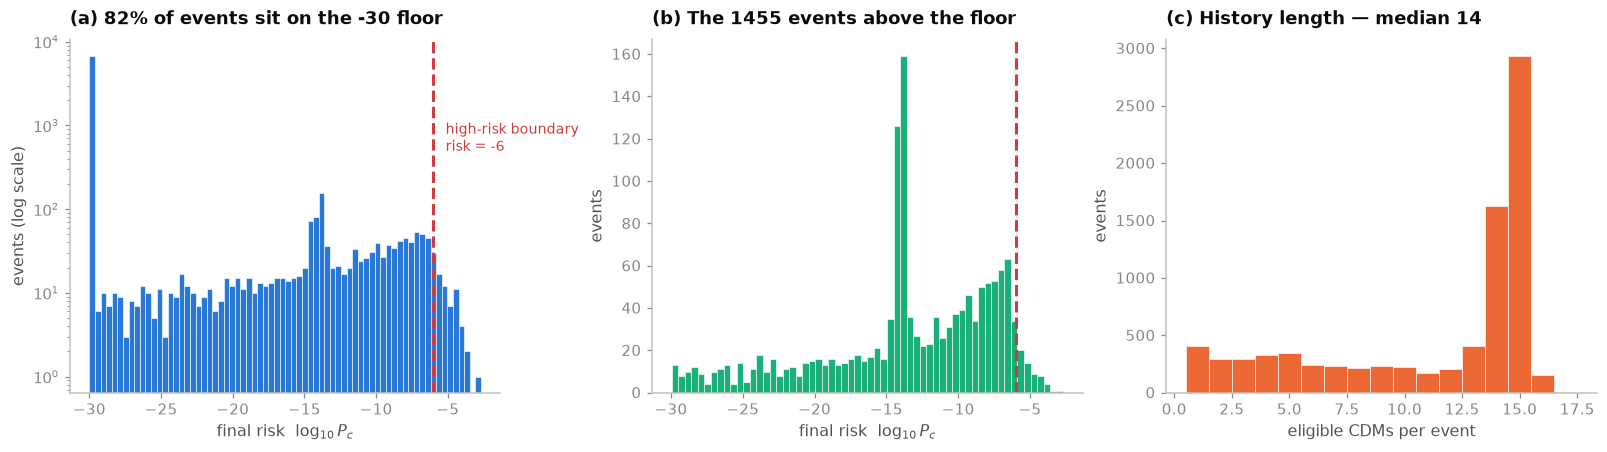

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.0))

ax = axes[0]
ax.hist(y_risk, bins=70, color=ps.SERIES[0], edgecolor="white", linewidth=0.4)
ax.axvline(rd.HIGH_RISK_THRESHOLD, color=ps.STATUS["critical"], linewidth=2, linestyle="--")
ax.annotate("high-risk boundary\nrisk = -6", xy=(rd.HIGH_RISK_THRESHOLD, 0.72),
            xycoords=("data", "axes fraction"), xytext=(8, 0), textcoords="offset points",
            fontsize=9, color=ps.STATUS["critical"], va="center")
ax.set_yscale("log")
ax.set_xlabel(r"final risk  $\log_{10} P_c$")
ax.set_ylabel("events (log scale)")
ax.set_title(f"(a) {np.mean(y_risk <= -29.999):.0%} of events sit on the -30 floor")
ps.grid_y_only(ax)

ax = axes[1]
informative = y_risk > -29.999
ax.hist(y_risk[informative], bins=60, color=ps.SERIES[2], edgecolor="white", linewidth=0.4)
ax.axvline(rd.HIGH_RISK_THRESHOLD, color=ps.STATUS["critical"], linewidth=2, linestyle="--")
ax.set_xlabel(r"final risk  $\log_{10} P_c$")
ax.set_ylabel("events")
ax.set_title(f"(b) The {informative.sum()} events above the floor")
ps.grid_y_only(ax)

ax = axes[2]
n_cdms = np.array([len(e) for e in X_events])
ax.hist(n_cdms, bins=np.arange(0.5, n_cdms.max() + 1.5), color=ps.SERIES[1],
        edgecolor="white", linewidth=0.4)
ax.set_xlabel("eligible CDMs per event")
ax.set_ylabel("events")
ax.set_title(f"(c) History length — median {int(np.median(n_cdms))}")
ps.grid_y_only(ax)

ps.save_fig(fig, "01_target_distribution", RESULTS_DIR)
plt.show()

Panel (a) is the single most important fact about this regression problem.
Predicting the constant $-30$ gives an MSE of
$\operatorname{Var}(r) \approx$ the number printed below, and any $R^2$ close to
zero means "no better than the floor". Panel (b) shows that the genuinely
informative events — the ones a useful model must get right — are a small
minority.

In [6]:
print(f"variance of the target (= MSE of predicting the mean): {y_risk.var():.2f}")
print(f"MSE of always predicting -30:                          {np.mean((y_risk + 30) ** 2):.2f}")
print(f"events above the floor: {informative.sum()} ({informative.mean():.1%})")
print(f"events at or above -6:  {(y_risk >= -6).sum()}")

variance of the target (= MSE of predicting the mean): 45.35
MSE of always predicting -30:                          53.60
events above the floor: 1455 (17.5%)
events at or above -6:  66


  saved ../results/regression/figures/02_feature_space.png


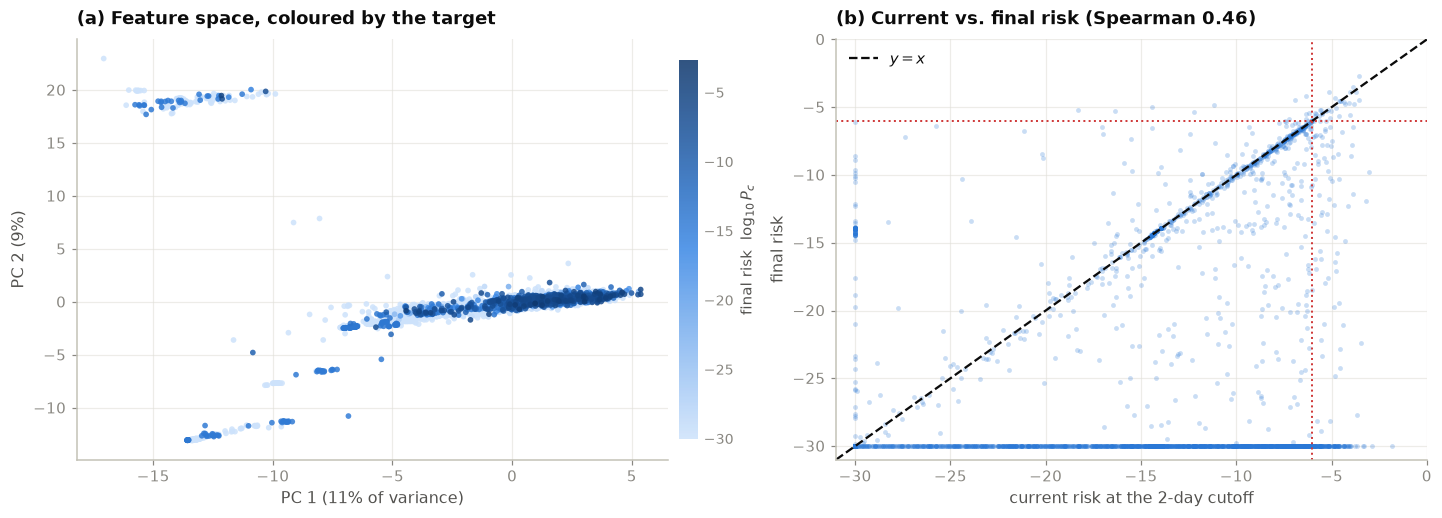

In [7]:
# PCA on the standardised event-level features, fitted on the training split
# only, coloured by the continuous target.
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED).fit(X_train)
Z_dev = pca.transform(X_dev)
order = np.argsort(y_dev)       # draw high-risk points last so they stay visible

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
# Light = the uninformative -30 floor, dark = high risk, so the rare events pop.
sc = ax.scatter(Z_dev[order, 0], Z_dev[order, 1], c=y_dev[order], s=14,
                cmap=ps.SEQ_CMAP, linewidths=0, alpha=0.85)
cb = fig.colorbar(sc, ax=ax, shrink=0.9, pad=0.02)
cb.set_label(r"final risk  $\log_{10} P_c$", color=ps.INK_SECONDARY, fontsize=10)
cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=9, colors=ps.INK_MUTED)
ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("(a) Feature space, coloured by the target")
ax.grid(True, alpha=0.6)

ax = axes[1]
risk_now = tables["train"]["risk"].values
ax.scatter(risk_now, y_train, s=10, alpha=0.25, color=ps.SERIES[0], linewidths=0)
lims = [-31, 0]
ax.plot(lims, lims, color=ps.INK, linestyle="--", linewidth=1.5, label="$y = x$")
ax.axhline(rd.HIGH_RISK_THRESHOLD, color=ps.STATUS["critical"], linewidth=1.3, linestyle=":")
ax.axvline(rd.HIGH_RISK_THRESHOLD, color=ps.STATUS["critical"], linewidth=1.3, linestyle=":")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("current risk at the 2-day cutoff")
ax.set_ylabel("final risk")
ax.set_title(f"(b) Current vs. final risk (Spearman "
             f"{spearmanr(risk_now, y_train).statistic:.2f})")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "02_feature_space", RESULTS_DIR)
plt.show()

Panel (b) shows why this problem is not trivial despite the strong
correlation: the cloud is wide, and in particular there is a band of events
whose current risk sits near $-30$ but whose final risk rises sharply. Those
are exactly the events a useful model has to catch, and they are the ones a
naive "the risk will stay where it is" rule misses.

## 3. Activation function × weight initialisation

Same protocol as the classification notebook: a fixed `[100, 100]` network,
everything held constant except the hidden activation and the initialiser,
scored by 5-fold CV on the development set. MSE is the training objective and
the selection metric.

In [8]:
ACTIVATIONS = ["sigmoid", "relu", "leaky_relu"]
INITS = ["lecun", "xavier", "he"]

act_init_results, _ = run_grid(
    base_reg(), {"activation": ACTIVATIONS, "initialization": INITS}, X_dev, y_dev
)
ps.save_table(act_init_results, "03_activation_initialization", RESULTS_DIR)
print(act_init_results[["activation", "initialization", "mse", "std_mse",
                        "mae", "r2", "mean_fit_time"]].to_string(index=False))

  9 configs x 5 folds in 347 s (best CV MSE = 29.866)
  saved ../results/regression/tables/03_activation_initialization.csv
activation initialization       mse  std_mse      mae       r2  mean_fit_time
   sigmoid             he 29.866015 2.921575 3.117603 0.339304      56.815372
   sigmoid         xavier 30.795246 2.685950 3.214641 0.318600      59.370872
   sigmoid          lecun 30.872872 2.608676 3.211997 0.316859      57.091331
      relu         xavier 31.010139 1.205700 3.732993 0.312243      43.917758
      relu          lecun 31.153703 1.187775 3.689207 0.308998      44.673811
leaky_relu          lecun 31.249369 1.443514 3.775142 0.307259      42.932994
leaky_relu         xavier 31.347624 1.070468 3.749936 0.304255      45.195005
      relu             he 31.833825 0.528930 3.771539 0.292753      45.079329
leaky_relu             he 32.093874 0.456964 3.769858 0.286726      35.605267


  saved ../results/regression/figures/03_activation_initialization.png


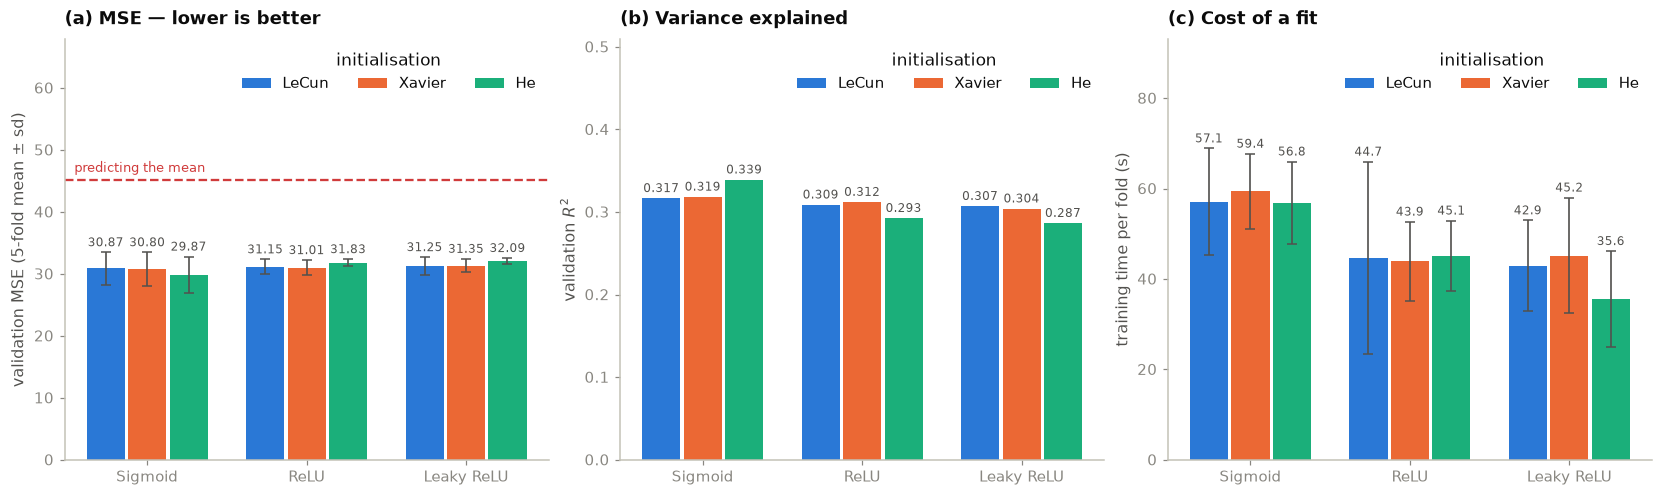

selected: activation = sigmoid, initialization = he (MSE = 29.866 +/- 2.922)


In [9]:
ACT_LABELS = {"sigmoid": "Sigmoid", "relu": "ReLU", "leaky_relu": "Leaky ReLU"}
INIT_LABELS = {"lecun": "LeCun", "xavier": "Xavier", "he": "He"}


def grouped_bars(ax, df, value, err=None, fmt="{:.2f}"):
    x = np.arange(len(ACTIVATIONS))
    width = 0.26
    for k, s in enumerate(INITS):
        vals, errs = [], []
        for g in ACTIVATIONS:
            row = df[(df["activation"] == g) & (df["initialization"] == s)]
            vals.append(float(row[value].iloc[0]) if len(row) else np.nan)
            errs.append(float(row[err].iloc[0]) if (err and len(row)) else 0.0)
        bars = ax.bar(x + (k - 1) * width, vals, width * 0.92, label=INIT_LABELS[s],
                      color=ps.SERIES[k], yerr=errs if err else None, capsize=3,
                      error_kw=dict(ecolor=ps.INK_SECONDARY, lw=1.1))
        ax.bar_label(bars, fmt=fmt.format, fontsize=8, color=ps.INK_SECONDARY, padding=2)
    ax.set_xticks(x, [ACT_LABELS[g] for g in ACTIVATIONS])
    ps.grid_y_only(ax)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))

ax = axes[0]
grouped_bars(ax, act_init_results, "mse", "std_mse")
ax.axhline(y_dev.var(), color=ps.STATUS["critical"], linestyle="--", linewidth=1.5)
ax.annotate("predicting the mean", xy=(0.02, y_dev.var()), xycoords=("axes fraction", "data"),
            xytext=(0, 5), textcoords="offset points", fontsize=8.5,
            color=ps.STATUS["critical"])
ax.set_ylabel(r"validation MSE (5-fold mean $\pm$ sd)")
ax.set_title("(a) MSE — lower is better")
ax.set_ylim(0, y_dev.var() * 1.5)
ax.legend(title="initialisation", ncols=3, loc="upper right")

ax = axes[1]
grouped_bars(ax, act_init_results, "r2", fmt="{:.3f}")
ax.set_ylabel(r"validation $R^2$")
ax.set_title("(b) Variance explained")
ax.set_ylim(0, act_init_results["r2"].max() * 1.5)
ax.legend(title="initialisation", ncols=3, loc="upper right")

ax = axes[2]
grouped_bars(ax, act_init_results, "mean_fit_time", "std_fit_time", fmt="{:.1f}")
ax.set_ylabel("training time per fold (s)")
ax.set_title("(c) Cost of a fit")
ax.set_ylim(0, (act_init_results["mean_fit_time"] + act_init_results["std_fit_time"]).max() * 1.35)
ax.legend(title="initialisation", ncols=3, loc="upper right")

ps.save_fig(fig, "03_activation_initialization", RESULTS_DIR)
plt.show()

best = act_init_results.iloc[0]
BEST_ACTIVATION, BEST_INIT = best["activation"], best["initialization"]
print(f"selected: activation = {BEST_ACTIVATION}, initialization = {BEST_INIT} "
      f"(MSE = {best['mse']:.3f} +/- {best['std_mse']:.3f})")

## 4. Network architecture

The same four shapes compared in the classification notebook, so the two
studies can be read side by side.

In [10]:
ARCHITECTURES = {
    "Single wide [200]": (200,),
    "Two equal [100, 100]": (100, 100),
    "Decreasing [128, 64, 32]": (128, 64, 32),
    "Increasing [32, 64, 128]": (32, 64, 128),
}

arch_results, _ = run_grid(
    base_reg(activation=BEST_ACTIVATION, initialization=BEST_INIT),
    {"hidden_dims": list(ARCHITECTURES.values())}, X_dev, y_dev,
)
label_of = {str(list(v)): k for k, v in ARCHITECTURES.items()}
arch_results["architecture"] = [label_of[str(list(h))] for h in arch_results["hidden_dims"]]
arch_results["parameters"] = [
    fc.count_parameters(fc.FFNN(N_FEATURES, h, BEST_ACTIVATION, BEST_INIT, 1))
    for h in arch_results["hidden_dims"]
]
ps.save_table(arch_results, "04_architectures", RESULTS_DIR)
print(arch_results[["architecture", "parameters", "mse", "std_mse", "mae", "r2",
                    "mean_fit_time"]].to_string(index=False))

  4 configs x 5 folds in 218 s (best CV MSE = 28.076)
  saved ../results/regression/tables/04_architectures.csv
            architecture  parameters       mse  std_mse      mae       r2  mean_fit_time
       Single wide [200]       25401 28.076274 1.462071 3.342027 0.377900      87.120089
Increasing [32, 64, 128]       14593 29.134548 1.380878 3.134735 0.353894      39.851283
    Two equal [100, 100]       22801 29.866015 2.921575 3.117603 0.339304      70.479318
Decreasing [128, 64, 32]       26497 32.181904 2.207820 3.484453 0.287377      54.107822


  saved ../results/regression/figures/04_architectures.png


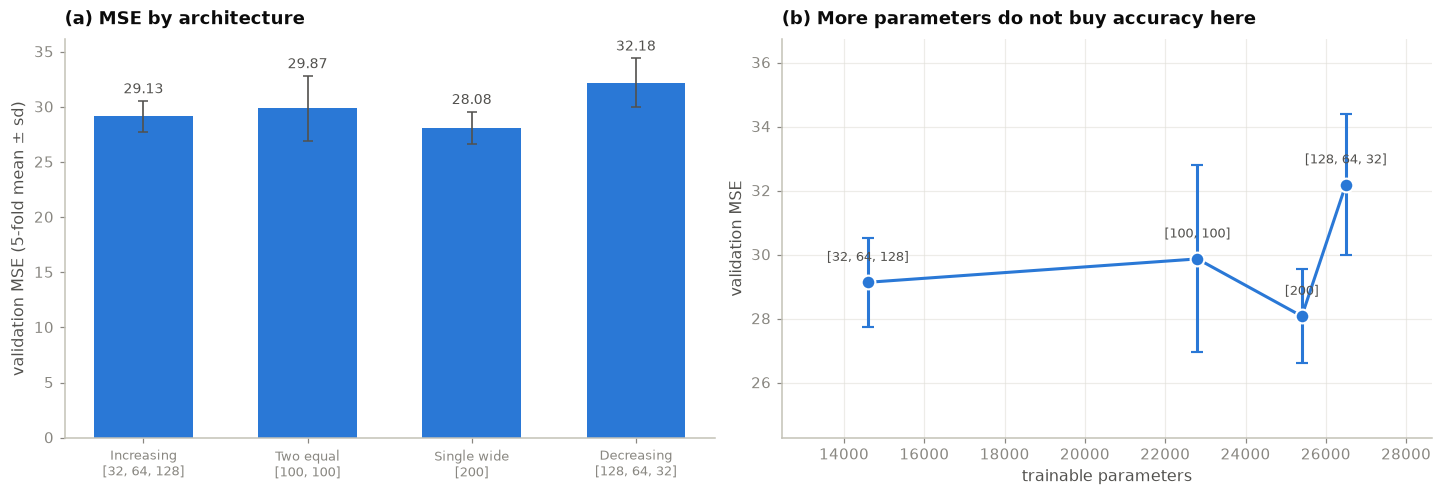

selected architecture: Single wide [200] -> [200]


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ordered = arch_results.sort_values("parameters")
labels = [a.replace(" [", "\n[") for a in ordered["architecture"]]

ax = axes[0]
bars = ax.bar(labels, ordered["mse"], color=ps.SERIES[0], width=0.6,
              yerr=ordered["std_mse"], capsize=3,
              error_kw=dict(ecolor=ps.INK_SECONDARY, lw=1.1))
ax.bar_label(bars, fmt="{:.2f}".format, fontsize=9, color=ps.INK_SECONDARY, padding=3)
ax.set_ylabel(r"validation MSE (5-fold mean $\pm$ sd)")
ax.set_title("(a) MSE by architecture")
ax.tick_params(axis="x", labelsize=8.5)
ps.grid_y_only(ax)

ax = axes[1]
ax.errorbar(ordered["parameters"], ordered["mse"], yerr=ordered["std_mse"],
            color=ps.SERIES[0], marker="o", markersize=9, capsize=4,
            markeredgecolor="white", markeredgewidth=1.4)
for _, r in ordered.iterrows():
    ax.annotate(str(list(r["hidden_dims"])), (r["parameters"], r["mse"]),
                textcoords="offset points", xytext=(0, 14), ha="center",
                fontsize=8.5, color=ps.INK_SECONDARY)
ax.margins(x=0.18, y=0.3)
ax.set_xlabel("trainable parameters")
ax.set_ylabel("validation MSE")
ax.set_title("(b) More parameters do not buy accuracy here")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "04_architectures", RESULTS_DIR)
plt.show()

BEST_HIDDEN = tuple(arch_results.iloc[0]["hidden_dims"])
print(f"selected architecture: {arch_results.iloc[0]['architecture']} -> {list(BEST_HIDDEN)}")

## 5. L1 vs. L2 regularisation

The two penalties are compared **separately**, never jointly, so that the
interpretation stays clean:

$$C_{L1} = \text{MSE} + \lambda_1 \sum_{i,j} |W_{ij}|, \qquad
  C_{L2} = \text{MSE} + \lambda_2 \sum_{i,j} W_{ij}^2 .$$

Both sums run over **weights only** — biases are never penalised, matching the
Project 2 derivation where $\partial C/\partial b_i = \delta_i$ regardless of
the penalty.

This section uses an explicit `ParameterGrid` loop rather than `GridSearchCV`,
because the quantities of interest include the *fitted weights themselves*
(their norm and how many are driven near zero), which a cross-validated score
does not expose.

In [12]:
LAMBDAS = [0.0, 1e-6, 1e-5, 1e-4, 1e-3]

reg_grid = list(ParameterGrid([
    {"penalty": ["none"], "lam": [0.0]},
    {"penalty": ["l1"], "lam": [l for l in LAMBDAS if l > 0]},
    {"penalty": ["l2"], "lam": [l for l in LAMBDAS if l > 0]},
]))

from joblib import Parallel, delayed

FOLDS = list(CV.split(X_dev))


def fit_fold_with_penalty(cfg, fold_id, tr, va):
    """One (penalty, lambda, fold) fit; returns scores plus weight diagnostics."""
    penalty, lam = cfg["penalty"], cfg["lam"]
    kwargs = {"l1_lambda": lam} if penalty == "l1" else ({"l2_lambda": lam} if penalty == "l2" else {})
    fc.set_seed(SEED)                          # identical init in every fold
    est = base_reg(hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION,
                   initialization=BEST_INIT, **kwargs)
    t0 = time.perf_counter()
    est.fit(X_dev[tr], y_dev[tr])
    fit_time = time.perf_counter() - t0
    pred = est.predict(X_dev[va])

    W = np.concatenate([w.detach().cpu().numpy().ravel() for w in fc.weight_matrices(est.model_)])
    return {
        "penalty": penalty, "lambda": lam, "fold": fold_id,
        "mse": mean_squared_error(y_dev[va], pred),
        "mae": mean_absolute_error(y_dev[va], pred),
        "r2": r2_score(y_dev[va], pred),
        "weight_l2_norm": float(np.linalg.norm(W)),
        # "Near zero" relative to the layer scale, so the measure is not an
        # artefact of how large the weights happen to be.
        "frac_near_zero": float(np.mean(np.abs(W) < 1e-3 * np.abs(W).max())),
        "fit_time_s": fit_time,
    }


t_start = time.perf_counter()
fold_rows = Parallel(n_jobs=N_JOBS)(
    delayed(fit_fold_with_penalty)(cfg, k, tr, va)
    for cfg in reg_grid for k, (tr, va) in enumerate(FOLDS)
)
print(f"{len(fold_rows)} fits in {time.perf_counter() - t_start:.0f} s")

per_fold = pd.DataFrame(fold_rows)
reg_results = (
    per_fold.groupby(["penalty", "lambda"], as_index=False)
    .agg(mse=("mse", "mean"), std_mse=("mse", "std"), mae=("mae", "mean"), r2=("r2", "mean"),
         weight_l2_norm=("weight_l2_norm", "mean"), frac_near_zero=("frac_near_zero", "mean"),
         fit_time_s=("fit_time_s", "mean"))
)
ps.save_table(reg_results, "05_regularization", RESULTS_DIR)

45 fits in 379 s
  saved ../results/regression/tables/05_regularization.csv


PosixPath('../results/regression/tables/05_regularization.csv')

  saved ../results/regression/figures/05_regularization.png


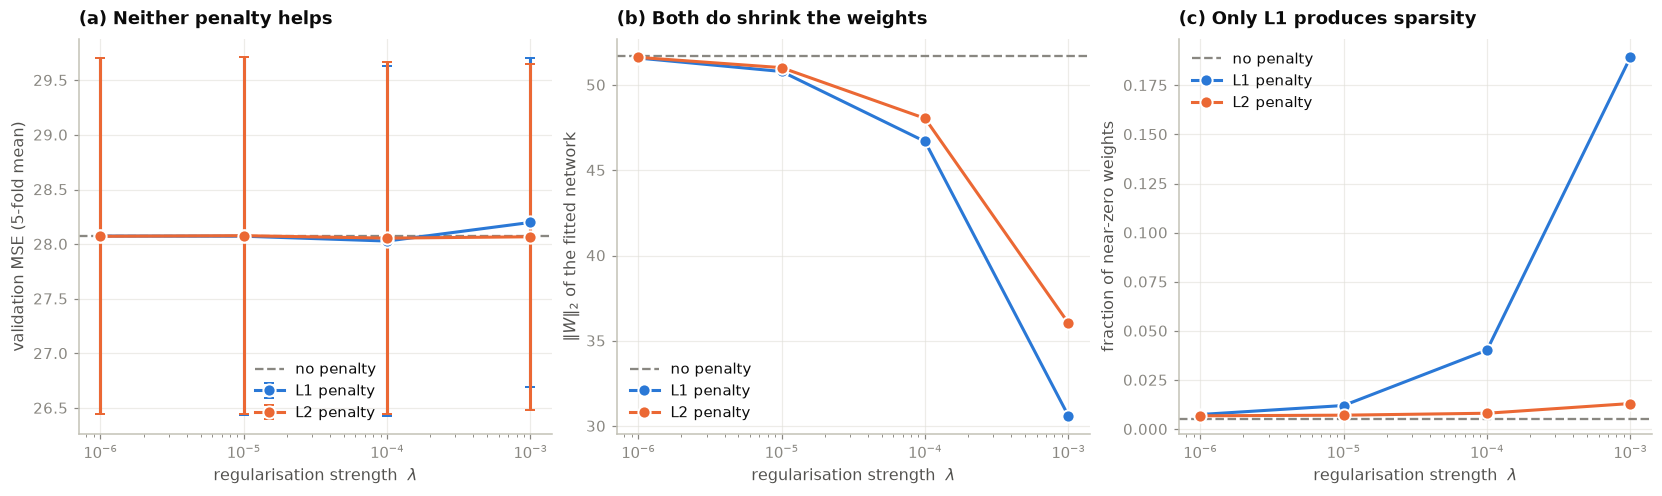

penalty   lambda       mse  std_mse      mae       r2  weight_l2_norm  frac_near_zero  fit_time_s
     l1 0.000001 28.074618 1.627514 3.341853 0.377926       51.581993        0.007524   66.256691
     l1 0.000010 28.073262 1.636798 3.341154 0.377968       50.793484        0.012103   53.312718
     l1 0.000100 28.028894 1.599206 3.335314 0.378889       46.689714        0.040262   42.889722
     l1 0.001000 28.199342 1.504707 3.362776 0.374992       30.608598        0.189230   36.777446
     l2 0.000001 28.072666 1.629526 3.341779 0.377973       51.621806        0.006873   39.155666
     l2 0.000010 28.078029 1.631143 3.342106 0.377855       51.018550        0.007183   65.010128
     l2 0.000100 28.055653 1.613869 3.338131 0.378325       48.044447        0.008167   76.116056
     l2 0.001000 28.068022 1.584194 3.348278 0.378013       36.043895        0.013103   50.603837
   none 0.000000 28.076274 1.634645 3.342027 0.377900       51.719415        0.005349   78.157099

selected regularisa

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
no_reg = reg_results[reg_results["penalty"] == "none"].iloc[0]
pos_lams = [l for l in LAMBDAS if l > 0]

for ax, (col, ylab, title) in zip(axes, [
    ("mse", "validation MSE (5-fold mean)", "(a) Neither penalty helps"),
    ("weight_l2_norm", r"$\|W\|_2$ of the fitted network", "(b) Both do shrink the weights"),
    ("frac_near_zero", "fraction of near-zero weights", "(c) Only L1 produces sparsity"),
]):
    for k, pen in enumerate(["l1", "l2"]):
        sub = reg_results[reg_results["penalty"] == pen].sort_values("lambda")
        yerr = sub["std_mse"] if col == "mse" else None
        ax.errorbar(sub["lambda"], sub[col], yerr=yerr, marker="o", markersize=8,
                    color=ps.SERIES[k], label=f"{pen.upper()} penalty", capsize=3,
                    markeredgecolor="white", markeredgewidth=1.3)
    ax.axhline(no_reg[col], color=ps.INK_MUTED, linestyle="--", linewidth=1.5,
               label="no penalty")
    ax.set_xscale("log")
    ax.set_xlabel(r"regularisation strength  $\lambda$")
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.6)

ps.save_fig(fig, "05_regularization", RESULTS_DIR)
plt.show()

print(reg_results.to_string(index=False))
BEST_REG = reg_results.sort_values("mse").iloc[0]
print(f"\nselected regularisation: {BEST_REG['penalty']} with lambda = {BEST_REG['lambda']:g}")

Panels (b) and (c) confirm the implementation is doing what the theory says —
both penalties shrink $\|W\|_2$ monotonically, and only L1 drives a growing
fraction of weights to (near) zero, because $\partial |W|/\partial W =
\operatorname{sign}(W)$ applies a constant pull towards the origin while the
L2 gradient $2\lambda W$ vanishes there.

Panel (a) is the result that matters: neither penalty beats no penalty at all.
As in the classification notebook, early stopping is already doing the
regularising, and an explicit weight penalty has nothing left to contribute.

## 6. Bias–variance decomposition by bootstrap

For a squared-error loss the expected test error decomposes as

$$\mathbb{E}\big[(y - \hat{f})^2\big] = \underbrace{\big(y - \mathbb{E}[\hat f]\big)^2}_{\text{bias}^2}
+ \underbrace{\operatorname{Var}(\hat f)}_{\text{variance}} + \sigma^2 .$$

**The dataset does not provide a known irreducible-noise variance $\sigma^2$.**
Unlike the Runge function in Project 2, where noise was added with a known
standard deviation of 0.1, here the "noise" is whatever the orbital dynamics
and the tracking process contribute, and it cannot be separated out. What
follows is therefore an **empirical bootstrap estimate**, not a closed-form
decomposition: the measured bias term absorbs $\sigma^2$, so bias² and variance
will not sum exactly to the test error.

Procedure: hold one fixed test subset out; for each architecture, train
$B = 20$ models on bootstrap resamples of the development set; predict the same
fixed subset with all of them; then

$$\widehat{\text{bias}^2} = \frac{1}{n}\sum_j \big(y_j - \bar{f}_j\big)^2,\qquad
\widehat{\operatorname{Var}} = \frac{1}{n}\sum_j \operatorname{Var}_b\big(\hat f_{bj}\big),\qquad
\widehat{\text{Err}} = \frac{1}{B}\frac{1}{n}\sum_b\sum_j \big(y_j - \hat f_{bj}\big)^2 .$$

In [14]:
COMPLEXITIES = {
    "[16]": (16,),
    "[32]": (32,),
    "[64]": (64,),
    "[100, 100]": (100, 100),
    "[128, 64, 32]": (128, 64, 32),
}

rng = np.random.default_rng(SEED)
# Draw every bootstrap index set up front so the resampling is reproducible
# regardless of the order in which the parallel workers finish.
boot_idx = {label: [rng.integers(0, len(y_dev), len(y_dev)) for _ in range(N_BOOTSTRAP)]
            for label in COMPLEXITIES}


def fit_bootstrap(label, hidden, b, idx):
    """Train one bootstrap model and predict the fixed test subset."""
    fc.set_seed(SEED + b)
    est = base_reg(hidden_dims=hidden, activation=BEST_ACTIVATION,
                   initialization=BEST_INIT, max_epochs=100, patience=15)
    est.fit(X_dev[idx], y_dev[idx])
    return label, b, est.predict(X_test)


t_start = time.perf_counter()
boot_preds = Parallel(n_jobs=N_JOBS)(
    delayed(fit_bootstrap)(label, hidden, b, boot_idx[label][b])
    for label, hidden in COMPLEXITIES.items() for b in range(N_BOOTSTRAP)
)

bv_rows = []
for label, hidden in COMPLEXITIES.items():
    preds = np.stack([p for (l, b, p) in sorted(boot_preds, key=lambda t: t[1]) if l == label])
    mean_pred = preds.mean(axis=0)
    bias2 = float(np.mean((y_test - mean_pred) ** 2))
    variance = float(np.mean(preds.var(axis=0)))
    error = float(np.mean([(y_test - preds[b]) ** 2 for b in range(N_BOOTSTRAP)]))
    n_params = fc.count_parameters(fc.FFNN(N_FEATURES, hidden, BEST_ACTIVATION, BEST_INIT, 1))
    bv_rows.append({"architecture": label, "parameters": n_params,
                    "bias_squared": bias2, "variance": variance, "test_mse": error})
    print(f"  {label:<16} params {n_params:>6}  bias^2 {bias2:7.3f}  "
          f"var {variance:7.3f}  MSE {error:7.3f}")

bias_variance = pd.DataFrame(bv_rows)
ps.save_table(bias_variance, "06_bias_variance", RESULTS_DIR)
print(f"\n{len(COMPLEXITIES) * N_BOOTSTRAP} bootstrap fits in "
      f"{time.perf_counter() - t_start:.0f} s")

  [16]             params   2033  bias^2  27.785  var   2.079  MSE  29.864
  [32]             params   4065  bias^2  27.005  var   1.882  MSE  28.887
  [64]             params   8129  bias^2  27.486  var   1.801  MSE  29.287
  [100, 100]       params  22801  bias^2  27.295  var   8.982  MSE  36.277
  [128, 64, 32]    params  26497  bias^2  29.174  var   9.115  MSE  38.289
  saved ../results/regression/tables/06_bias_variance.csv

100 bootstrap fits in 472 s


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


  saved ../results/regression/figures/06_bias_variance.png


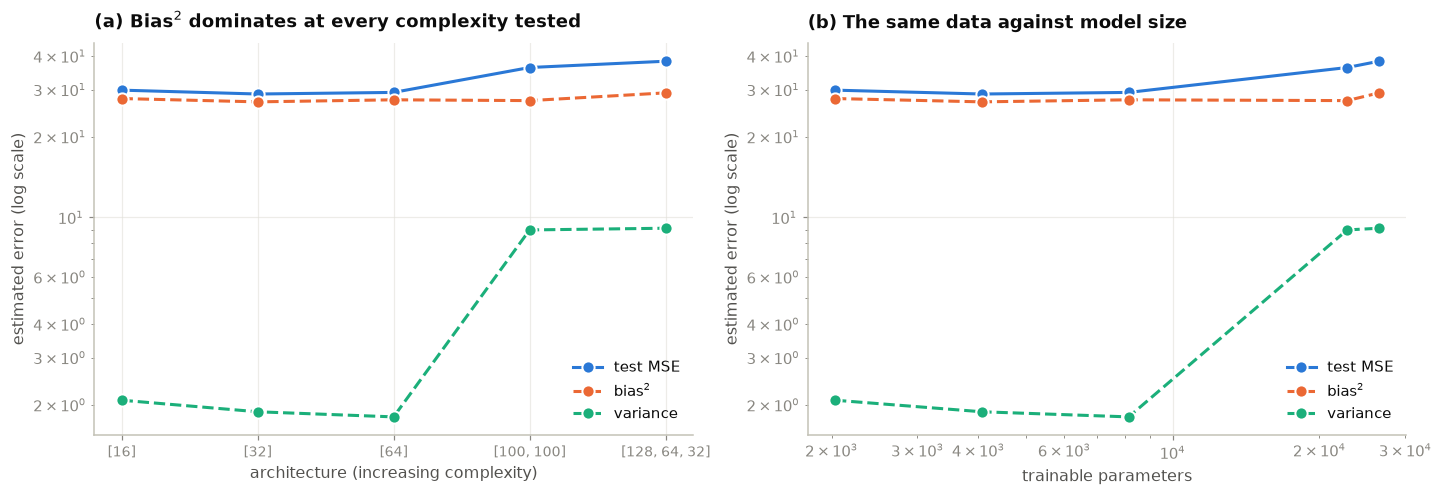

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

for ax, xcol, xlabel, logx in [
    (axes[0], "architecture", "architecture (increasing complexity)", False),
    (axes[1], "parameters", "trainable parameters", True),
]:
    xs = range(len(bias_variance)) if xcol == "architecture" else bias_variance["parameters"]
    for k, (col, lbl) in enumerate([("test_mse", "test MSE"),
                                    ("bias_squared", r"bias$^2$"),
                                    ("variance", "variance")]):
        ax.plot(xs, bias_variance[col], marker="o", markersize=8, color=ps.SERIES[k],
                label=lbl, markeredgecolor="white", markeredgewidth=1.3,
                linestyle="-" if col == "test_mse" else "--")
    if xcol == "architecture":
        ax.set_xticks(range(len(bias_variance)), bias_variance["architecture"], fontsize=9)
    if logx:
        ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("estimated error (log scale)")
    ax.legend()
    ax.grid(True, alpha=0.6)

axes[0].set_title(r"(a) Bias$^2$ dominates at every complexity tested")
axes[1].set_title("(b) The same data against model size")

ps.save_fig(fig, "06_bias_variance", RESULTS_DIR)
plt.show()

Bias² sits at ≈ 27–29 for every architecture and is the dominant term
throughout — but remember that it also contains the unknown irreducible
noise, so "bias" here really means "everything a single CDM cannot predict".
The variance term is where the classical trade-off shows: it stays near 2 for
the one-layer networks and then jumps to ≈ 9 for the two- and three-layer
ones, and the test MSE rises with it. The deeper networks are fitting the
particular bootstrap sample rather than the signal, exactly what the
decomposition is meant to expose — and exactly what a single-split comparison
(§4) could not see, because there the deeper nets looked merely *not better*.
The same figure in Project 2 (Runge, Fig. 7) showed variance two orders of
magnitude below bias; here the gap is a factor of 3–15, and it closes as the
network grows.

## 7. Learning curves of the selected model

  saved ../results/regression/tables/07_learning_curves.csv
stopped after 101 epochs; best epoch 81 (val MSE 27.331); 6.4 s


  saved ../results/regression/figures/07_learning_curves.png


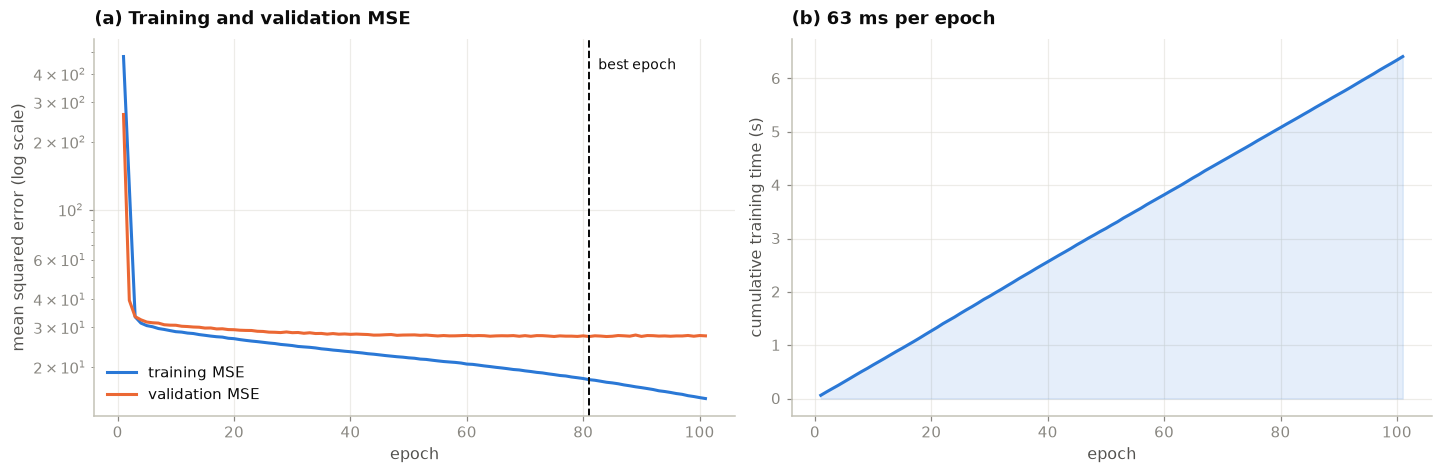

In [16]:
fc.set_seed(SEED)
curve_model = fc.FFNN(N_FEATURES, BEST_HIDDEN, BEST_ACTIVATION, BEST_INIT, 1)
curve_model, history = fc.train_model(
    curve_model, X_train, y_train, X_val, y_val,
    task="regression", loss_name="mse", lr=BASE_LR,
    batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS, patience=PATIENCE,
    grad_clip=GRAD_CLIP, device=DEVICE,
)
hist_df = pd.DataFrame({k: history[k] for k in
                        ("train_loss", "val_loss", "val_score", "epoch_time", "cum_time")})
hist_df.insert(0, "epoch", np.arange(1, len(hist_df) + 1))
ps.save_table(hist_df, "07_learning_curves", RESULTS_DIR)
print(f"stopped after {history['n_epochs']} epochs; best epoch {history['best_epoch']} "
      f"(val MSE {history['best_score']:.3f}); {history['total_time']:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
ax.plot(hist_df["epoch"], hist_df["train_loss"], color=ps.SERIES[0], label="training MSE")
ax.plot(hist_df["epoch"], hist_df["val_loss"], color=ps.SERIES[1], label="validation MSE")
ax.axvline(history["best_epoch"], color=ps.INK, linestyle="--", linewidth=1.3)
ax.annotate("best epoch", xy=(history["best_epoch"], 0.95),
            xycoords=("data", "axes fraction"), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color=ps.INK, va="top")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("mean squared error (log scale)")
ax.set_title("(a) Training and validation MSE")
ax.legend()
ax.grid(True, alpha=0.6)

ax = axes[1]
ax.plot(hist_df["epoch"], hist_df["cum_time"], color=ps.SERIES[0])
ax.fill_between(hist_df["epoch"], 0, hist_df["cum_time"], color=ps.SERIES[0], alpha=0.12)
ax.set_xlabel("epoch")
ax.set_ylabel("cumulative training time (s)")
ax.set_title(f"(b) {hist_df['epoch_time'].mean() * 1000:.0f} ms per epoch")
ax.grid(True, alpha=0.6)

ps.save_fig(fig, "07_learning_curves", RESULTS_DIR)
plt.show()

## 8. Final evaluation on the held-out test set

In [17]:
fc.set_seed(SEED)
final_kwargs = ({"l1_lambda": BEST_REG["lambda"]} if BEST_REG["penalty"] == "l1"
                else {"l2_lambda": BEST_REG["lambda"]} if BEST_REG["penalty"] == "l2" else {})
final_model = base_reg(hidden_dims=BEST_HIDDEN, activation=BEST_ACTIVATION,
                       initialization=BEST_INIT, **final_kwargs)
t0 = time.perf_counter()
final_model.fit(X_dev, y_dev)
final_train_time = time.perf_counter() - t0
test_pred_raw = final_model.predict(X_test)
test_pred = clip_risk(test_pred_raw)

final_row = regression_metrics("FFNN (this notebook)", y_test, test_pred_raw, final_train_time)
final_results = pd.DataFrame([final_row])
ps.save_table(final_results, "08_final_test_results", RESULTS_DIR)
for k, v in final_row.items():
    print(f"  {k:<18} {v}")

  saved ../results/regression/tables/08_final_test_results.csv
  model              FFNN (this notebook)
  mse                27.401940500832982
  mse_unclipped      27.687702703940282
  rmse               5.234686284853466
  mae                3.0760686918853564
  r2                 0.4050920414208643
  spearman           0.5247054754711408
  train_time_s       6.577173411000331
  mse_informative    98.67647265264496
  mae_informative    8.594011055571693
  n_informative      224
  mse_highrisk       225.8427525079739
  mae_highrisk       14.740447330474854
  n_highrisk         10
  kelvins_score      nan


  saved ../results/regression/figures/08_predictions_residuals.png


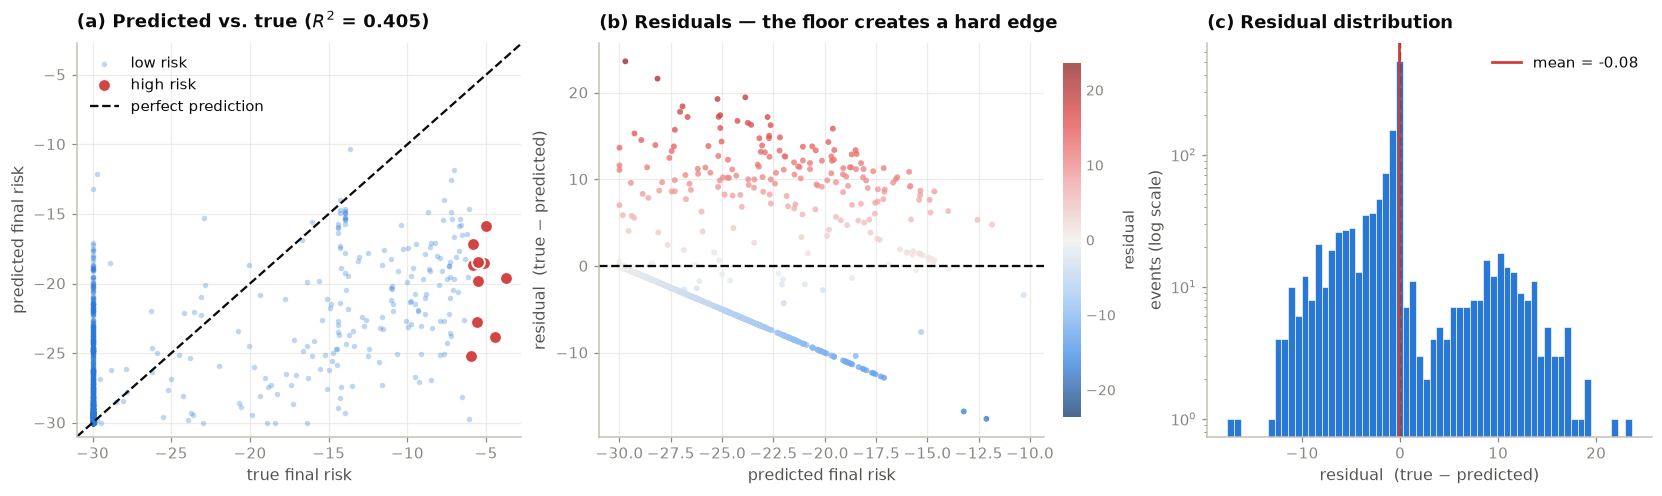

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
resid = y_test - test_pred
high_mask = y_test >= rd.HIGH_RISK_THRESHOLD

ax = axes[0]
ax.scatter(y_test[~high_mask], test_pred[~high_mask], s=13, alpha=0.3,
           color=ps.SERIES[0], linewidths=0, label="low risk")
ax.scatter(y_test[high_mask], test_pred[high_mask], s=70, alpha=0.95,
           color=ps.STATUS["critical"], edgecolors="white", linewidths=1.3,
           label="high risk", zorder=3)
lims = [min(y_test.min(), test_pred.min()) - 1, max(y_test.max(), test_pred.max()) + 1]
ax.plot(lims, lims, color=ps.INK, linestyle="--", linewidth=1.5, label="perfect prediction")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("true final risk")
ax.set_ylabel("predicted final risk")
ax.set_title(f"(a) Predicted vs. true ($R^2$ = {final_row['r2']:.3f})")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.6)

ax = axes[1]
# Diverging colour: the residual's *sign* is the thing being read.
sc = ax.scatter(test_pred, resid, c=resid, cmap=ps.DIV_CMAP, s=15, linewidths=0,
                alpha=0.75, vmin=-np.abs(resid).max(), vmax=np.abs(resid).max())
ax.axhline(0, color=ps.INK, linestyle="--", linewidth=1.5)
cb = fig.colorbar(sc, ax=ax, shrink=0.9, pad=0.02)
cb.set_label("residual", color=ps.INK_SECONDARY, fontsize=10)
cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=9, colors=ps.INK_MUTED)
ax.set_xlabel("predicted final risk")
ax.set_ylabel("residual  (true $-$ predicted)")
ax.set_title("(b) Residuals — the floor creates a hard edge")
ax.grid(True, alpha=0.6)

ax = axes[2]
ax.hist(resid, bins=60, color=ps.SERIES[0], edgecolor="white", linewidth=0.4)
ax.axvline(0, color=ps.INK, linestyle="--", linewidth=1.5)
ax.axvline(resid.mean(), color=ps.STATUS["critical"], linewidth=1.8,
           label=f"mean = {resid.mean():+.2f}")
ax.set_yscale("log")
ax.set_xlabel("residual  (true $-$ predicted)")
ax.set_ylabel("events (log scale)")
ax.set_title("(c) Residual distribution")
ax.legend()
ps.grid_y_only(ax)

ps.save_fig(fig, "08_predictions_residuals", RESULTS_DIR)
plt.show()

## 9. Benchmark against classical baselines

Every baseline sees the same features, the same development set and the same
frozen test set, and every prediction is clipped to the physical range
$[-30, 0]$ before scoring. The untrained baseline is the persistence rule:
**predict that the risk will stay exactly where the last pre-cutoff CDM put
it.**

The clipping is not cosmetic. One test event carries a `t_time_lastob_start`
value 9 600 training standard deviations from the mean — a single anomalous
CDM — and an unclipped linear model extrapolates it to a predicted risk in the
hundreds or more, which alone inflates the OLS test MSE by five orders of
magnitude. Networks with bounded activations and tree ensembles are immune to
this by construction; linear models are not. `mse_unclipped` in the table
records the damage.

In [19]:
BASELINES = {
    "Predict the mean": DummyRegressor(strategy="mean"),
    "Linear regression (OLS)": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=SEED),
    "Lasso": Lasso(alpha=0.01, max_iter=20000, random_state=SEED),
    "Random forest": RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=N_JOBS),
    "Gradient boosting": HistGradientBoostingRegressor(random_state=SEED),
}

bench_rows = []

# (i) the untrained persistence rule
bench_rows.append(regression_metrics(
    "Rule: risk stays unchanged", y_test, tables["test"]["risk"].values, 0.0))

# (ii) trained baselines
for name, model in BASELINES.items():
    t0 = time.perf_counter()
    model.fit(X_dev, y_dev)
    tt = time.perf_counter() - t0
    bench_rows.append(regression_metrics(name, y_test, model.predict(X_test), tt))

# (iii) the selected FFNN
bench_rows.append(final_row)

benchmark = pd.DataFrame(bench_rows).sort_values("mse").reset_index(drop=True)
ps.save_table(benchmark, "09_benchmark", RESULTS_DIR)
print(benchmark[["model", "mse", "mse_unclipped", "rmse", "mae", "r2", "spearman",
                 "mse_informative", "mse_highrisk", "train_time_s"]].to_string(index=False))

/tmp/ipykernel_15655/3786828891.py:79: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  "spearman": float(spearmanr(y_true, y_pred).statistic),


  saved ../results/regression/tables/09_benchmark.csv
                     model       mse  mse_unclipped     rmse      mae        r2  spearman  mse_informative  mse_highrisk  train_time_s
         Gradient boosting 24.406386   2.442890e+01 4.940282 2.628352  0.470127  0.555253        84.278854    142.637054      0.842265
             Random forest 24.696716   2.469672e+01 4.969579 2.737201  0.463824  0.573374        85.650092    187.345229     46.298990
      FFNN (this notebook) 27.401941   2.768770e+01 5.234686 3.076069  0.405092  0.524705        98.676473    225.842753      6.577173
                     Ridge 30.301672   3.266335e+02 5.504695 3.475397  0.342138  0.508578       107.796153    248.162031      0.087699
   Linear regression (OLS) 30.381973   1.446374e+07 5.511984 3.451869  0.340394  0.515413       108.376369    251.694424      0.585943
                     Lasso 30.388441   5.955650e+02 5.512571 3.494720  0.340254  0.510347       108.987874    251.202581      0.154416
 

  saved ../results/regression/figures/09_benchmark.png


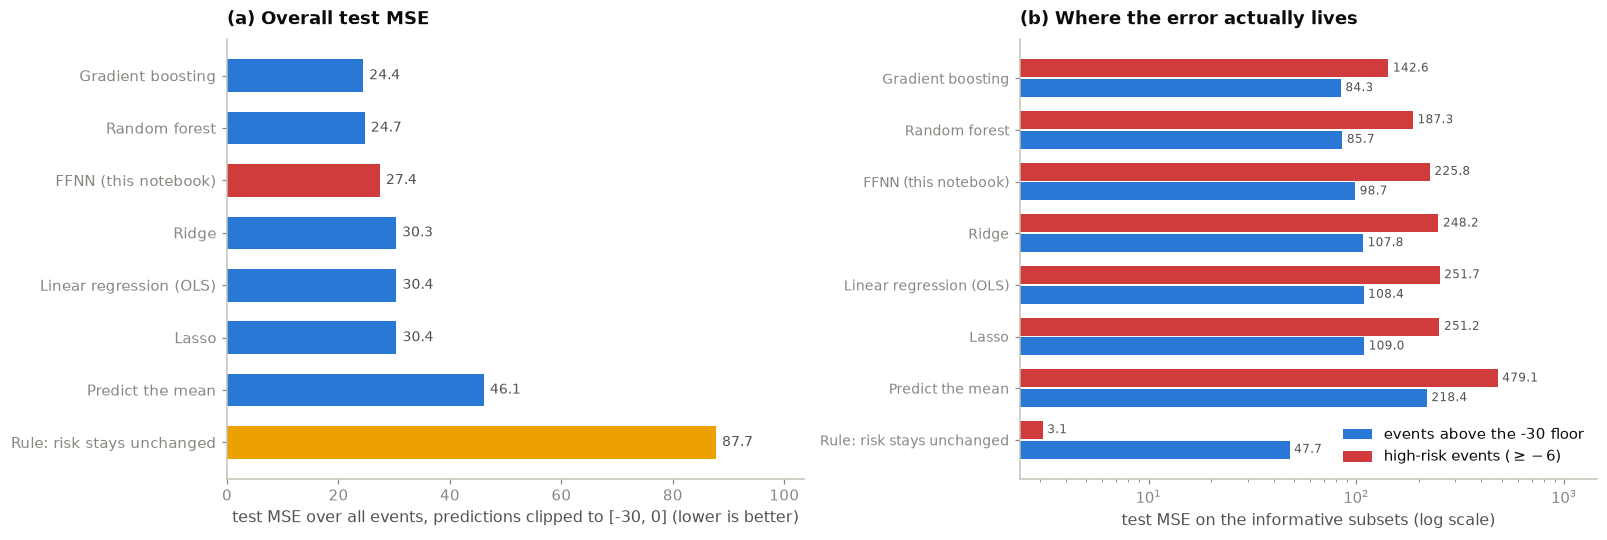

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
ordered = benchmark.sort_values("mse", ascending=False)
colors = [ps.STATUS["critical"] if "FFNN" in m else
          (ps.SERIES[3] if m.startswith("Rule") else ps.SERIES[0]) for m in ordered["model"]]

ax = axes[0]
bars = ax.barh(ordered["model"], ordered["mse"], color=colors, height=0.62)
ax.bar_label(bars, fmt="{:.1f}".format, fontsize=9, color=ps.INK_SECONDARY, padding=4)
ax.set_xlabel("test MSE over all events, predictions clipped to [-30, 0] (lower is better)")
ax.set_xlim(0, ordered["mse"].max() * 1.18)
ax.set_title("(a) Overall test MSE")
ps.grid_x_only(ax)

ax = axes[1]
x = np.arange(len(ordered))
w = 0.38
b1 = ax.barh(x - w / 2, ordered["mse_informative"], w * 0.92, color=ps.SERIES[0],
             label="events above the -30 floor")
b2 = ax.barh(x + w / 2, ordered["mse_highrisk"], w * 0.92, color=ps.STATUS["critical"],
             label="high-risk events ($\\geq -6$)")
ax.bar_label(b1, fmt="{:.1f}".format, fontsize=8, color=ps.INK_SECONDARY, padding=3)
ax.bar_label(b2, fmt="{:.1f}".format, fontsize=8, color=ps.INK_SECONDARY, padding=3)
ax.set_yticks(x, ordered["model"], fontsize=9)
ax.set_xscale("log")
ax.set_xlim(right=max(ordered["mse_informative"].max(), ordered["mse_highrisk"].max()) * 3)
ax.set_xlabel("test MSE on the informative subsets (log scale)")
ax.set_title("(b) Where the error actually lives")
ax.legend(loc="lower right")
ps.grid_x_only(ax)

ps.save_fig(fig, "09_benchmark", RESULTS_DIR)
plt.show()

## Summary

* **The censored target dominates everything.** 82 % of events end at exactly
  $-30$, so an impressive-looking overall $R^2$ mostly measures how well a
  model reproduces the floor. Splitting the error across the three subsets
  (§1, §9b) is what makes the numbers interpretable.
* **Activation, initialiser and architecture barely matter** (§3, §4), just as
  in the classification notebook — differences sit inside the fold-to-fold
  spread, and a 25 000-parameter network does no better than a 16-unit one.
* **Neither L1 nor L2 improves on no penalty** (§5), although both demonstrably
  shrink the weights and only L1 produces sparsity. Early stopping is already
  the binding constraint.
* **Bias² dominates, but variance is where the architectures differ** (§6):
  it rises from ≈ 2 for one hidden layer to ≈ 9 for two or three, and the
  bootstrap test MSE rises with it. The deeper networks are starting to fit
  the sample rather than the signal. The bias term folds in the unknown
  irreducible noise, so the ceiling is the information in a single CDM.
* **Tree ensembles beat the FFNN** by a few MSE points overall (§9); the
  **persistence rule** is the best model on the informative subset but the
  worst trained-or-untrained model overall, because it cannot know which
  events will collapse to the floor. **Linear models fail catastrophically
  without clipping** — a single anomalous CDM in the test set is enough —
  which is a practical argument for bounded models on this kind of data.

Limitations: only 10 high-risk events in the test split, so `mse_highrisk` has
very wide error bars; the `latest` single-CDM representation discards the
trajectory of the risk estimate over the preceding days, which the RNN notebook
in this repository is designed to exploit; and bootstrap resampling of events
with $B = 20$ gives a noisy variance estimate.